In [104]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")   

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import PROCESSED,POINTS ,SLIPPAGE_POINTS,SPREAD_FLOOR,REPORTS
from scipy.stats import kurtosis


In [106]:
df = pd.read_parquet(PROCESSED)

In [107]:
#Candle info
df["r"] = np.log(df["close"] / df["close"].shift(1)) *100
df = df.dropna()
df["r"].describe().round(5)

count    479968.00000
mean          0.00021
std           0.06857
min          -2.12514
25%          -0.02655
50%           0.00050
75%           0.02751
max           2.85712
Name: r, dtype: float64

In [108]:
#Curtosis
curt=kurtosis(df["r"].dropna(),fisher=False)
#Extreme
sigma = df["r"].std()
extreme_candle = df["r"].abs() > 4 * sigma     
extreme =extreme_candle.mean() * 100  
print(f"Curtosis value: {curt.round(2)}")
print(f"The % of extreme candles is {extreme.round(2)}%")


Curtosis value: 48.39
The % of extreme candles is 0.74%


Text(0, 0.5, '€')

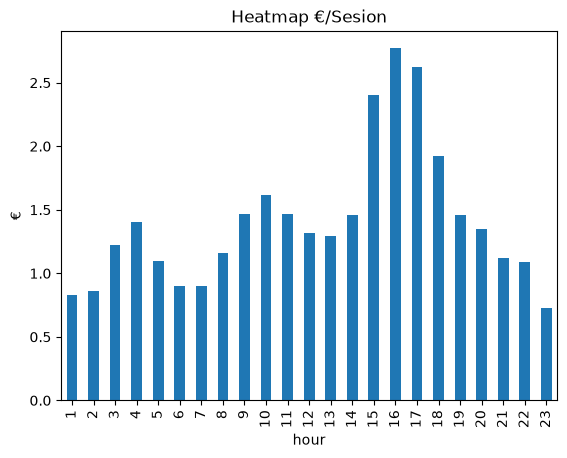

In [109]:
#Volatility per H and Y 
df["rango"]= df["high"] - df["low"]
g = df.groupby(df.index.hour)["rango"]
vol_hour = pd.DataFrame({"mediana": g.median(),
              "p95": g.quantile(0.95)})

vol_hour["mediana"].plot(kind="bar")
plt.title("Heatmap €/Sesion")           
plt.xlabel("hour")                        
plt.ylabel("€") 
              

Text(0, 0.5, '€ movements')

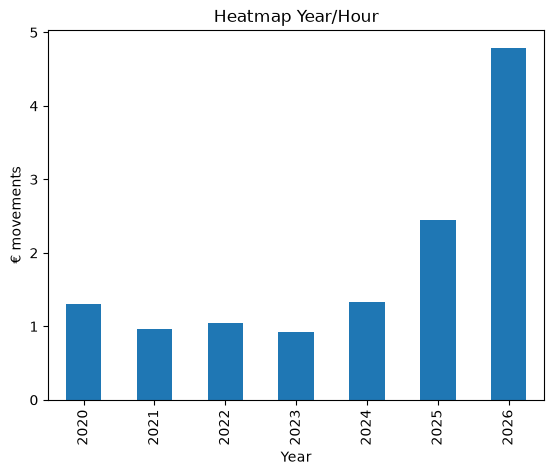

In [110]:
df["rango"]= df["high"] - df["low"]
g = df.groupby(df.index.year)["rango"]
vol_year = pd.DataFrame({"mediana": g.median(),
              "p95": g.quantile(0.95)})

vol_year["mediana"].plot(kind="bar")
plt.title("Heatmap Year/Hour")           
plt.xlabel("Year")                        
plt.ylabel("€ movements") 

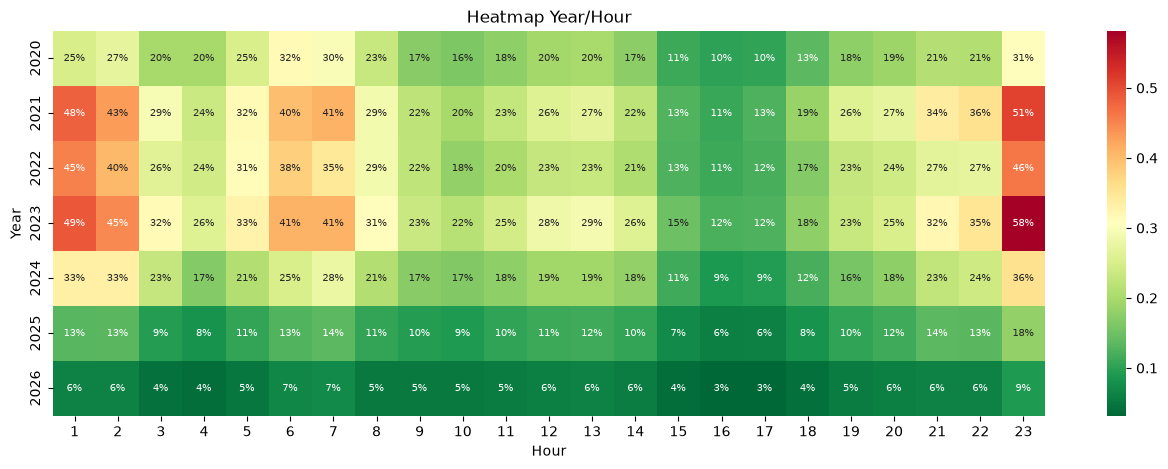

In [111]:
heatmap = df.groupby([df.index.year, df.index.hour])["rango"].median().unstack()
cost =  (((SPREAD_FLOOR + SLIPPAGE_POINTS) * POINTS) / heatmap)
plt.figure(figsize=(16, 5))  
sns.heatmap(cost,
            annot=True,
            annot_kws={"size": 7}, 
            fmt=".0%",
            cmap="RdYlGn_r")
plt.title("Heatmap Year/Hour")           
plt.xlabel("Hour")                        
plt.ylabel("Year")
plt.savefig(REPORTS / "relative_cost_hour_year.png", dpi=150, bbox_inches="tight")                        
plt.show() 